# Flight Price Prediction: Modelling
Uses the cleaned data from `01_data_exploration.ipynb`. Steps: encode text columns, split into train and test sets,
train a baseline Linear Regression, evaluate it, then try a Random Forest.

In [2]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../Data/flights_clean.csv")
print("Shape:", df.shape)
df.head()

Shape: (300153, 10)


,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


## 1. Encoding text columns
`stops` has a real order (price rose steadily with each stop), so it becomes 0/1/2. `class` has two values, so it becomes 0/1.
The other text columns have no order and get one yes/no column per category.

In [4]:
df_model = df.copy()

df_model["stops"] = df_model["stops"].map({"zero": 0, "one": 1, "two_or_more": 2})
df_model["class"] = df_model["class"].map({"Economy": 0, "Business": 1})

print("Missing after mapping:")
print(df_model[["stops", "class"]].isna().sum())
df_model[["stops", "class"]].head()

Missing after mapping:
stops    0
class    0
dtype: int64


,stops,class
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0


In [5]:
nominal_cols = ["airline", "source_city", "destination_city", "departure_time", "arrival_time"]

df_model = pd.get_dummies(df_model, columns=nominal_cols, drop_first=True, dtype=int)

print("Shape after encoding:", df_model.shape)
df_model.head()

Shape after encoding: (300153, 30)


,stops,class,duration,days_left,price,airline_Air_India,airline_GO_FIRST,airline_Indigo,airline_SpiceJet,airline_Vistara,...,departure_time_Early_Morning,departure_time_Evening,departure_time_Late_Night,departure_time_Morning,departure_time_Night,arrival_time_Early_Morning,arrival_time_Evening,arrival_time_Late_Night,arrival_time_Morning,arrival_time_Night
0,0,0,2.17,1,5953,0,0,0,1,0,...,0,1,0,0,0,0,0,0,0,1
1,0,0,2.33,1,5953,0,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0
2,0,0,2.17,1,5956,0,0,0,0,0,...,1,0,0,0,0,1,0,0,0,0
3,0,0,2.25,1,5955,0,0,0,0,1,...,0,0,0,1,0,0,0,0,0,0
4,0,0,2.33,1,5955,0,0,0,0,1,...,0,0,0,1,0,0,0,0,1,0


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor

## 2. Train/test split
80% of rows train the model; 20% are held back to test it on flights it has never seen.

In [8]:
X = df_model.drop(columns=["price"])
y = df_model["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training rows:", X_train.shape)
print("Test rows:    ", X_test.shape)

Training rows: (240122, 29)
Test rows:     (60031, 29)


In [9]:
## 3. Baseline model: Linear Regression

lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

comparison = pd.DataFrame({
    "actual": y_test.values[:10],
    "predicted": y_pred_lr[:10].round()
})
comparison

,actual,predicted
0,7366,3151.0
1,64831,54896.0
2,6195,9857.0
3,60160,54718.0
4,6578,6050.0
5,4555,9048.0
6,23838,49494.0
7,3860,5990.0
8,32230,49689.0
9,76841,58758.0


In [10]:
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print(f"MAE:  ₹{mae_lr:,.0f}")
print(f"RMSE: ₹{rmse_lr:,.0f}")
print(f"R²:   {r2_lr:.3f}")
print("Negative predictions:", (y_pred_lr < 0).sum())

MAE:  ₹4,501
RMSE: ₹6,815
R²:   0.910
Negative predictions: 2629


In [11]:
##error split by class

results = pd.DataFrame({
    "class": X_test["class"].map({0: "Economy", 1: "Business"}),
    "actual": y_test,
    "predicted": y_pred_lr
})
results["abs_error"] = (results["actual"] - results["predicted"]).abs()

summary = results.groupby("class").agg(
    MAE=("abs_error", "mean"),
    median_price=("actual", "median"),
    negatives=("predicted", lambda p: (p < 0).sum())
)
summary["MAE_as_%_of_price"] = (summary["MAE"] / summary["median_price"] * 100).round(1)
summary.round(0)

,MAE,median_price,negatives,MAE_as_%_of_price
class,,,,
Business,8357.0,53164.0,0,16.0
Economy,2754.0,5772.0,2629,48.0


**Baseline result (Linear Regression):** R² = 0.910, MAE = ₹4,501, RMSE = ₹6,815.
The high R² is mostly from separating Economy and Business. Split by class, Economy errors average ₹2,754 (48% of the median fare)
and all 2,629 negative predictions are Economy tickets. Business errors average ₹8,357 (16%).
Likely cause: a linear model has one weight per feature for both classes, so it can't capture effects that differ by class
(e.g. a stop adds ~₹2,400 in Economy but ~₹26,700 in Business), or the stepped days-left pattern from Finding 3.

## 4. Random Forest
Many decision trees, each trained on a random sample, with predictions averaged. Trees can learn steps and class-specific effects
that the linear model missed, and cannot predict negative prices.

In [14]:
rf = RandomForestRegressor(n_estimators=50, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print(f"MAE:  ₹{mae_rf:,.0f}")
print(f"RMSE: ₹{rmse_rf:,.0f}")
print(f"R²:   {r2_rf:.3f}")
print("Negative predictions:", (y_pred_rf < 0).sum())

MAE:  ₹1,090
RMSE: ₹2,811
R²:   0.985
Negative predictions: 0


In [15]:
## Random Forest error by class

results_rf = pd.DataFrame({
    "class": X_test["class"].map({0: "Economy", 1: "Business"}),
    "actual": y_test,
    "predicted": y_pred_rf
})
results_rf["abs_error"] = (results_rf["actual"] - results_rf["predicted"]).abs()

summary_rf = results_rf.groupby("class").agg(
    MAE=("abs_error", "mean"),
    median_price=("actual", "median")
)
summary_rf["MAE_as_%_of_price"] = (summary_rf["MAE"] / summary_rf["median_price"] * 100).round(1)
summary_rf.round(0)

,MAE,median_price,MAE_as_%_of_price
class,,,
Business,2147.0,53164.0,4.0
Economy,611.0,5772.0,11.0


**Random Forest result:** R² = 0.985, MAE = ₹1,090, RMSE = ₹2,811, no negative predictions.
MAE is about 76% lower than the linear baseline. By class: Economy error fell from 48% to 11% of the median fare (₹611),
Business from 16% to 4% (₹2,147). Trees can learn class-specific effects and stepped patterns that the linear model could not.

In [17]:
y_train_pred_rf = rf.predict(X_train)
mae_train_rf = mean_absolute_error(y_train, y_train_pred_rf)

print(f"Train MAE: ₹{mae_train_rf:,.0f}")
print(f"Test MAE:  ₹{mae_rf:,.0f}")

Train MAE: ₹425
Test MAE:  ₹1,090


**Overfitting check:** Train MAE ₹425 vs test MAE ₹1,090. The forest fits its training data closely (normal for Random Forests),
but the test error is still about 4× lower than the linear baseline, so it generalises well. Tuning (e.g. `min_samples_leaf`) could narrow the gap.

class                      0.880
duration                   0.059
days_left                  0.019
airline_Vistara            0.005
airline_Air_India          0.005
source_city_Delhi          0.004
destination_city_Delhi     0.004
source_city_Mumbai         0.002
destination_city_Mumbai    0.002
source_city_Kolkata        0.002
dtype: float64


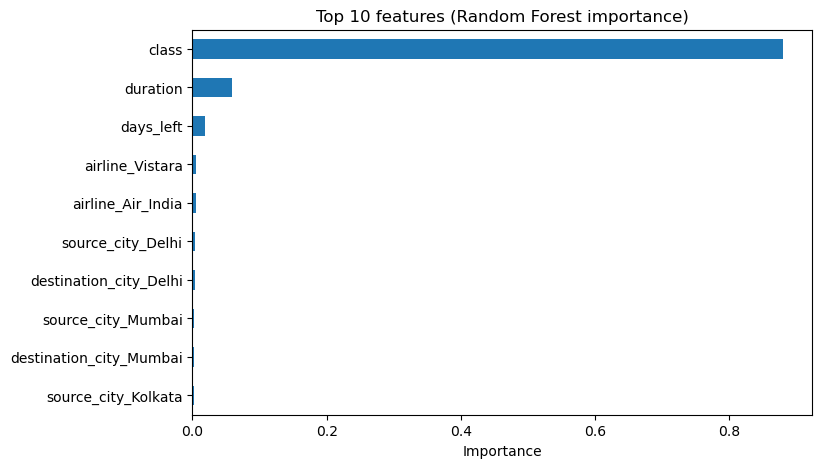

In [19]:
importances = pd.Series(rf.feature_importances_, index=X_train.columns)
importances = importances.sort_values(ascending=False)

print(importances.head(10).round(3))

importances.head(10).sort_values().plot(kind="barh", figsize=(8, 5),
                                       title="Top 10 features (Random Forest importance)")
plt.xlabel("Importance")
plt.show()

**Feature importance:** `class` dominates (0.880), matching Finding 1. `duration` (0.059) and `days_left` (0.019) follow.
Vistara and Air India are the top airlines, the only two selling Business. Departure and arrival time don't reach the top 10,
matching their weak effect in EDA. `stops` is also missing, likely because `duration` already carries that information
(non-stop ≈ 2 hours vs ≈ 12 hours with a stop, Finding 6), so the two features share the credit.

In [21]:
os.makedirs("../Models", exist_ok=True)

model_bundle = {"model": rf, "columns": list(X_train.columns)}
joblib.dump(model_bundle, "../Models/flight_price_rf.joblib", compress=3)

size_mb = os.path.getsize("../Models/flight_price_rf.joblib") / 1024**2
print(f"Saved model: {size_mb:.0f} MB")

Saved model: 86 MB


## 6. Predicting a single flight
`predict_price()` turns plain inputs into the 29-column format the model was trained on, and returns a predicted price.

In [23]:
def predict_price(airline, source_city, destination_city, flight_class,
                  stops, days_left, duration, departure_time, arrival_time):
    # 1. An empty form: one row, 29 columns, all zeros
    row = pd.DataFrame(0, index=[0], columns=model_bundle["columns"])

    # 2. Number columns
    row["stops"] = {"zero": 0, "one": 1, "two_or_more": 2}[stops]
    row["class"] = {"Economy": 0, "Business": 1}[flight_class]
    row["duration"] = duration
    row["days_left"] = days_left

    # 3. Switch on the right yes/no columns
    choices = {"airline": airline, "source_city": source_city,
               "destination_city": destination_city,
               "departure_time": departure_time, "arrival_time": arrival_time}
    for col, value in choices.items():
        if value not in df[col].unique():
            raise ValueError(f"Unknown {col}: '{value}'. Options: {sorted(df[col].unique())}")
        if f"{col}_{value}" in row.columns:
            row[f"{col}_{value}"] = 1

    # 4. Ask the model
    return round(model_bundle["model"].predict(row)[0])

In [24]:
price = predict_price(airline="Vistara", source_city="Delhi", destination_city="Mumbai",
                      flight_class="Economy", stops="zero", days_left=5, duration=2.25,
                      departure_time="Morning", arrival_time="Morning")
print(f"Predicted price: ₹{price:,}")

similar = df[(df["airline"] == "Vistara") & (df["source_city"] == "Delhi") &
             (df["destination_city"] == "Mumbai") & (df["class"] == "Economy") &
             (df["stops"] == "zero") & (df["days_left"] == 5)]
print("Matching real tickets:", len(similar))
print(f"Their median price: ₹{similar['price'].median():,.0f}")

Predicted price: ₹6,082
Matching real tickets: 15
Their median price: ₹5,955


In [25]:
import re
from datetime import date

CITIES = {"delhi": "Delhi", "mumbai": "Mumbai", "bombay": "Mumbai",
          "bangalore": "Bangalore", "bengaluru": "Bangalore",
          "kolkata": "Kolkata", "calcutta": "Kolkata",
          "hyderabad": "Hyderabad", "chennai": "Chennai", "madras": "Chennai"}

AIRLINES = {"vistara": "Vistara", "air india": "Air_India", "indigo": "Indigo",
            "spicejet": "SpiceJet", "airasia": "AirAsia", "air asia": "AirAsia",
            "go first": "GO_FIRST", "gofirst": "GO_FIRST"}

NUMBER_WORDS = {"two": 2, "three": 3, "four": 4, "five": 5, "six": 6,          # NEW
                "seven": 7, "eight": 8, "nine": 9, "ten": 10}
WEEKDAYS = ["monday", "tuesday", "wednesday", "thursday",                        # NEW
            "friday", "saturday", "sunday"]

def parse_question(question):
    q = question.lower()

    # Cities, in the order they appear in the question
    found = []
    for word, city in CITIES.items():
        position = q.find(word)
        if position != -1:
            found.append((position, city))
    found.sort()
    cities = [city for position, city in found]

    # Prefer explicit "from X" / "to Y"; fall back to word order
    from_city = next((city for word, city in CITIES.items() if f"from {word}" in q), None)
    to_city = next((city for word, city in CITIES.items() if f"to {word}" in q), None)
    source = from_city or next((c for c in cities if c != to_city), None)
    others = [c for c in cities if c != source]
    destination = to_city or (others[0] if others else None)

    # Days left
    q_num = q                                                                    # NEW
    for word, number in NUMBER_WORDS.items():                                    # NEW
        q_num = re.sub(rf"\b{word}\b", str(number), q_num)
    day_match = re.search(r"(\d+)\s*days?", q_num)
    week_match = re.search(r"(\d+)\s*weeks?", q_num)                             # NEW
    weekday = next((d for d in WEEKDAYS if d in q), None)                        # NEW

    if day_match:
        days_left = int(day_match.group(1))
    elif week_match:                                                             # NEW
        days_left = int(week_match.group(1)) * 7
    elif "fortnight" in q:                                                       # NEW
        days_left = 14
    elif "day after tomorrow" in q:                                              # NEW
        days_left = 2
    elif "tomorrow" in q:
        days_left = 1
    elif "next week" in q or "a week" in q:                                      # CHANGED
        days_left = 7
    elif weekday:                                                                # NEW
        days_ahead = (WEEKDAYS.index(weekday) - date.today().weekday()) % 7
        days_left = days_ahead if days_ahead > 0 else 7
    else:
        days_left = None

    # Airline, class and stops
    airline = next((name for word, name in AIRLINES.items() if word in q), None)
    flight_class = "Business" if "business" in q else "Economy"
    stops = "zero" if any(w in q for w in ["non-stop", "nonstop", "direct"]) else None

    return {"source_city": source,
            "destination_city": destination,
            "days_left": days_left, "flight_class": flight_class,
            "airline": airline, "stops": stops}

In [26]:
print(parse_question("How much is a flight from Delhi to Mumbai in 5 days?"))
print(parse_question("Business class Bombay to Bengaluru tomorrow on Vistara"))
print(parse_question("Price for a direct flight from Chennai to Kolkata"))

{'source_city': 'Delhi', 'destination_city': 'Mumbai', 'days_left': 5, 'flight_class': 'Economy', 'airline': None, 'stops': None}
{'source_city': 'Mumbai', 'destination_city': 'Bangalore', 'days_left': 1, 'flight_class': 'Business', 'airline': 'Vistara', 'stops': None}
{'source_city': 'Chennai', 'destination_city': 'Kolkata', 'days_left': None, 'flight_class': 'Economy', 'airline': None, 'stops': 'zero'}


In [27]:
def quote_price(source_city, destination_city, days_left, flight_class="Economy",
                airline=None, stops=None, departure_time=None, arrival_time=None):
    route = df[(df["source_city"] == source_city) &
               (df["destination_city"] == destination_city) &
               (df["class"] == flight_class)]
    if len(route) == 0:
        raise ValueError(f"I have no {flight_class} flights from {source_city} to {destination_city}.")
    if airline is not None and airline not in route["airline"].values:                  # ADDED
        raise ValueError(f"I have no {flight_class} {airline} flights on this route.")  # ADDED

    assumed = {}
    # Decide stops first...
    if stops is None:
        stops = route["stops"].mode()[0];                     assumed["stops"] = stops
    matching = route[route["stops"] == stops]
    if len(matching) == 0:
        raise ValueError(f"I have no {stops}-stop {flight_class} flights on this route.")

    # ...then pick everything else from flights with those stops
    if airline is None:
        airline = matching["airline"].mode()[0];              assumed["airline"] = airline
    elif airline not in matching["airline"].values:
        raise ValueError(f"{airline} has no {flight_class} flights with that number of stops on this route.")  # CHANGED
    matching = matching[matching["airline"] == airline]
    if departure_time is None:
        departure_time = matching["departure_time"].mode()[0]; assumed["departure_time"] = departure_time
    if arrival_time is None:
        arrival_time = matching["arrival_time"].mode()[0];     assumed["arrival_time"] = arrival_time
    duration = matching["duration"].median()

    price = predict_price(airline, source_city, destination_city, flight_class,
                          stops, days_left, duration, departure_time, arrival_time)
    return price, assumed

In [28]:
def ask(question, reader=parse_question):
    d = reader(question)

    # Ask back if something essential is missing
    if d["source_city"] is None or d["destination_city"] is None:
        return "Which two cities are you flying between? For example: Delhi to Mumbai."
    if d["days_left"] is None:
        return "How many days from now is the flight? For example: in 5 days, or tomorrow."
    if not 1 <= d["days_left"] <= 49:
        return "I can only estimate flights 1 to 49 days ahead, because that's what my data covers."

    try:
        price, assumed = quote_price(**d)
    except ValueError as problem:
        return str(problem)

    article = "An" if d["flight_class"] == "Economy" else "A"
    day_word = "day" if d["days_left"] == 1 else "days"
    reply = (f"{article} {d['flight_class']} flight from {d['source_city']} to {d['destination_city']} "
             f"in {d['days_left']} {day_word} should cost around ₹{price:,}.")
    if assumed:
        details = ", ".join(f"{key.replace('_', ' ')}: {str(value).replace('_', ' ')}"
                            for key, value in assumed.items())
        reply += f" (Assumed {details}.)"
    return reply

In [29]:
questions = [
    "How much is a flight from Delhi to Mumbai in 5 days?",
    "Business class Bombay to Bengaluru tomorrow on Vistara",
    "Direct flight from Chennai to Kolkata in 20 days",
    "Price for a flight to Hyderabad next week",
    "Delhi to Mumbai, business, on IndiGo, in 10 days",
]
for q in questions:
    print("Q:", q)
    print("A:", ask(q))
    print()

Q: How much is a flight from Delhi to Mumbai in 5 days?
A: An Economy flight from Delhi to Mumbai in 5 days should cost around ₹9,062. (Assumed stops: one, airline: Air India, departure time: Evening, arrival time: Night.)

Q: Business class Bombay to Bengaluru tomorrow on Vistara
A: A Business flight from Mumbai to Bangalore in 1 day should cost around ₹77,626. (Assumed stops: one, departure time: Morning, arrival time: Night.)

Q: Direct flight from Chennai to Kolkata in 20 days
A: An Economy flight from Chennai to Kolkata in 20 days should cost around ₹4,683. (Assumed airline: Indigo, departure time: Evening, arrival time: Night.)

Q: Price for a flight to Hyderabad next week
A: Which two cities are you flying between? For example: Delhi to Mumbai.

Q: Delhi to Mumbai, business, on IndiGo, in 10 days
A: I have no Business Indigo flights on this route.



In [30]:
print(ask("I want to fly to Mumbai from Delhi in 5 days"))
print(ask("What's the fare Delhi to Mumbai on Friday?"))
print(ask("Cheapest way to get from Chennai to Hyderabad in two weeks"))

An Economy flight from Delhi to Mumbai in 5 days should cost around ₹9,062. (Assumed stops: one, airline: Air India, departure time: Evening, arrival time: Night.)
An Economy flight from Delhi to Mumbai in 2 days should cost around ₹12,887. (Assumed stops: one, airline: Air India, departure time: Evening, arrival time: Night.)
An Economy flight from Chennai to Hyderabad in 14 days should cost around ₹10,208. (Assumed stops: one, airline: Vistara, departure time: Morning, arrival time: Night.)


In [31]:
print(ask("What's the fare Delhi to Mumbai on Friday?"))
print(ask("Cheapest way to get from Chennai to Hyderabad in two weeks"))
print(ask("Delhi to Kolkata in a fortnight"))
print(ask("Mumbai to Chennai the day after tomorrow"))

An Economy flight from Delhi to Mumbai in 2 days should cost around ₹12,887. (Assumed stops: one, airline: Air India, departure time: Evening, arrival time: Night.)
An Economy flight from Chennai to Hyderabad in 14 days should cost around ₹10,208. (Assumed stops: one, airline: Vistara, departure time: Morning, arrival time: Night.)
An Economy flight from Delhi to Kolkata in 14 days should cost around ₹10,430. (Assumed stops: one, airline: Air India, departure time: Evening, arrival time: Morning.)
An Economy flight from Mumbai to Chennai in 2 days should cost around ₹12,581. (Assumed stops: one, airline: Air India, departure time: Early Morning, arrival time: Night.)


## 7. Connecting to a local LLM (Ollama)
A small open model (Qwen 2.5, 3B) runs locally through Ollama. It is used only to understand questions; all prices come from the Random Forest.

In [33]:
!pip install -U typing_extensions
!pip install ollama

In [34]:
import ollama

response = ollama.chat(
    model="qwen2.5:3b",
    messages=[
        {"role": "system", "content": "You extract flight details. Reply with only the name of the departure city, nothing else."},
        {"role": "user", "content": "I want to fly to Mumbai from Delhi in 5 days"},
    ],
)
print(response["message"]["content"])

Delhi


In [35]:
import json
from datetime import date

CITY_NAMES = sorted(df["source_city"].unique())
AIRLINE_NAMES = sorted(df["airline"].unique())

schema = {
    "type": "object",
    "properties": {
        "source_city":      {"type": "string", "enum": CITY_NAMES + ["unknown"]},
        "destination_city": {"type": "string", "enum": CITY_NAMES + ["unknown"]},
        "days_left":        {"type": "integer"},
        "weekday":          {"type": "string", "enum": WEEKDAYS + ["unknown"]},
        "day_of_month":     {"type": "integer"},
        "flight_class":     {"type": "string", "enum": ["Economy", "Business"]},
        "airline":          {"type": "string", "enum": AIRLINE_NAMES + ["unknown"]},
        "stops":            {"type": "string", "enum": ["zero", "one", "two_or_more", "unknown"]},
    },
    "required": ["source_city", "destination_city", "days_left", "weekday", "day_of_month",
                 "flight_class", "airline", "stops"],
}

def days_until_day_of_month(day):
    today = date.today()
    for months_ahead in range(3):
        year = today.year + (today.month - 1 + months_ahead) // 12
        month = (today.month - 1 + months_ahead) % 12 + 1
        try:
            target = date(year, month, day)
        except ValueError:          # e.g. the 31st in a 30-day month
            continue
        if target > today:
            return (target - today).days
    return None

def llm_parse_question(question):
    today = date.today()
    instructions = (
        "Extract flight details from the user's question. "
        "source_city is where they fly FROM; destination_city is where they fly TO. "
        "Old city names: Bombay = Mumbai, Bengaluru = Bangalore, Calcutta = Kolkata, Madras = Chennai. "
        "If they give a number of days or weeks, put the total number of days in days_left "
        "(tomorrow = 1, a week = 7, a fortnight = 14), otherwise 0. "
        "If they name a day of the week, put it in weekday, otherwise 'unknown'. "
        "If they give a date like 'the 25th', put 25 in day_of_month, otherwise 0. "
        "flight_class is Economy unless they ask for business class. "
        "stops is 'zero' only if they ask for a direct or non-stop flight. "
        "Use 'unknown' for anything not mentioned. Do not guess."
    )
    response = ollama.chat(
        model="qwen2.5:3b",
        messages=[{"role": "system", "content": instructions},
                  {"role": "user", "content": question}],
        format=schema,
        options={"temperature": 0},
    )
    d = json.loads(response["message"]["content"])

    # Turn "unknown" and 0 into None
    for key in ["source_city", "destination_city", "airline", "stops"]:
        if d[key] == "unknown":
            d[key] = None

    # Python does the date maths from what the LLM extracted
    if d["weekday"] in WEEKDAYS:
        days_ahead = (WEEKDAYS.index(d["weekday"]) - today.weekday()) % 7
        d["days_left"] = days_ahead if days_ahead > 0 else 7
    elif d["day_of_month"] > 0:
        d["days_left"] = days_until_day_of_month(d["day_of_month"])
    elif d["days_left"] <= 0:
        d["days_left"] = None
    del d["weekday"], d["day_of_month"]      # keep the same keys as parse_question()

    # Rules first for dates: they're exact when they recognise the phrasing
    rules = parse_question(question)
    if rules["days_left"] is not None:
        d["days_left"] = rules["days_left"]

    # Guardrails: overrule details the question never mentioned
    q = question.lower()

    # NEW: city guardrail - keep the LLM's city only if it's really mentioned; otherwise use the rules'
    for key in ["source_city", "destination_city"]:
        city = d[key]
        mentioned = city is not None and any(word in q for word, name in CITIES.items() if name == city)
        if not mentioned:
            d[key] = rules[key]

    if d["stops"] == "zero" and not any(w in q for w in ["direct", "non-stop", "nonstop", "non stop"]):
        d["stops"] = None
    if d["stops"] in ["one", "two_or_more"] and "stop" not in q:
        d["stops"] = None
    if d["airline"] is not None and not any(word in q for word, name in AIRLINES.items()
                                            if name == d["airline"]):
        d["airline"] = None
    if d["flight_class"] == "Business" and "business" not in q:
        d["flight_class"] = "Economy"
    return d

In [36]:
tests = [
    "I want to fly to Mumbai from Delhi in 5 days",
    "Leaving Bombay for Calcutta this Saturday, business class",
    "Need a non-stop to Chennai from Hyderabad in about a fortnight",
    "Can I get from Bengaluru to Delhi on IndiGo three weeks from now?",
]
for q in tests:
    print("Q:    ", q)
    print("Rules:", parse_question(q))
    print("LLM:  ", llm_parse_question(q))
    print()

Q:     I want to fly to Mumbai from Delhi in 5 days
Rules: {'source_city': 'Delhi', 'destination_city': 'Mumbai', 'days_left': 5, 'flight_class': 'Economy', 'airline': None, 'stops': None}
LLM:   {'source_city': 'Delhi', 'destination_city': 'Mumbai', 'days_left': 5, 'flight_class': 'Economy', 'airline': None, 'stops': None}

Q:     Leaving Bombay for Calcutta this Saturday, business class
Rules: {'source_city': 'Mumbai', 'destination_city': 'Kolkata', 'days_left': 3, 'flight_class': 'Business', 'airline': None, 'stops': None}
LLM:   {'source_city': 'Mumbai', 'destination_city': 'Kolkata', 'days_left': 3, 'flight_class': 'Business', 'airline': None, 'stops': None}

Q:     Need a non-stop to Chennai from Hyderabad in about a fortnight
Rules: {'source_city': 'Hyderabad', 'destination_city': 'Chennai', 'days_left': 14, 'flight_class': 'Economy', 'airline': None, 'stops': 'zero'}
LLM:   {'source_city': 'Hyderabad', 'destination_city': 'Chennai', 'days_left': 14, 'flight_class': 'Economy', '

In [37]:
tests_1 = [
    "Leaving Bombay for Calcutta this Saturday, business class",
    "Heading out of Madras to Delhi on the 25th",
    "Bengaluru to Hyderabad, end of next week",
    "I need to be in Mumbai by Friday, flying from Kolkata",
]
for q in tests_1:
    print("Q:    ", q)
    print("Rules:", parse_question(q))
    print("LLM:  ", llm_parse_question(q))
    print()

Q:     Leaving Bombay for Calcutta this Saturday, business class
Rules: {'source_city': 'Mumbai', 'destination_city': 'Kolkata', 'days_left': 3, 'flight_class': 'Business', 'airline': None, 'stops': None}
LLM:   {'source_city': 'Mumbai', 'destination_city': 'Kolkata', 'days_left': 3, 'flight_class': 'Business', 'airline': None, 'stops': None}

Q:     Heading out of Madras to Delhi on the 25th
Rules: {'source_city': 'Chennai', 'destination_city': 'Delhi', 'days_left': None, 'flight_class': 'Economy', 'airline': None, 'stops': None}
LLM:   {'source_city': 'Chennai', 'destination_city': 'Delhi', 'days_left': 7, 'flight_class': 'Economy', 'airline': None, 'stops': None}

Q:     Bengaluru to Hyderabad, end of next week
Rules: {'source_city': 'Bangalore', 'destination_city': 'Hyderabad', 'days_left': 7, 'flight_class': 'Economy', 'airline': None, 'stops': None}
LLM:   {'source_city': 'Bangalore', 'destination_city': 'Hyderabad', 'days_left': 7, 'flight_class': 'Economy', 'airline': None, 'st

In [ ]:
print(llm_parse_question("I want to fly to Mumbai from Delhi in 5 days"))

In [ ]:
for q in tests_1:
    print("Q:", q)
    print("A:", ask(q, reader=llm_parse_question))
    print()